In [1]:
import ast
import heapq
import itertools
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from collections import deque
import math

In [2]:
from google.colab import files

uploaded = files.upload()

filename = next(iter(uploaded.keys()))

print("Uploaded file:", filename)

Saving Environment.txt to Environment.txt
Uploaded file: Environment.txt


In [3]:
def parse_coordinates(text):
    coordinates = ast.literal_eval(text.strip())

    # Convert a single coordinate into a list
    if (
        isinstance(coordinates, tuple)
        and len(coordinates) == 2
        and all(isinstance(x, int) for x in coordinates)
    ):
        coordinates = [coordinates]

    return [tuple(point) for point in coordinates]


def load_environment(filename):

    with open(filename, "r") as file:
        lines = [line.strip() for line in file if line.strip()]

    # Read grid dimensions
    rows, cols = map(int, lines[0].split(","))

    # Read obstacle information
    obstacle_count = int(lines[1])
    obstacles = set(parse_coordinates(lines[2]))

    # Read dirty location information
    dirty_count = int(lines[3])
    dirty_locations = parse_coordinates(lines[4])

    # Read charging station
    charging_station = parse_coordinates(lines[5])[0]

    grid = {
        "rows": rows,
        "cols": cols,
        "obstacles": obstacles,
        "dirty_locations": dirty_locations,
        "charging_station": charging_station
    }

    return grid

In [4]:
grid = load_environment(filename)

print("Grid Size:", grid["rows"], "x", grid["cols"])
print("Obstacles:", grid["obstacles"])
print("Dirty Locations:", grid["dirty_locations"])
print("Charging Station:", grid["charging_station"])

Grid Size: 8 x 8
Obstacles: {(2, 4), (6, 5), (0, 0), (6, 1), (7, 3), (0, 5), (3, 6), (3, 2)}
Dirty Locations: [(5, 3), (4, 4), (1, 2), (6, 7)]
Charging Station: (0, 7)


In [5]:
def validate_environment(grid):

    rows = grid["rows"]
    cols = grid["cols"]
    obstacles = grid["obstacles"]
    dirty = grid["dirty_locations"]
    charging = grid["charging_station"]

    errors = []

    # Check grid dimensions
    if rows < 8 or cols < 8:
        errors.append("Grid must be at least 8x8.")

    # Check obstacle count
    if len(obstacles) < 6:
        errors.append("At least 6 obstacles are required.")

    # Check dirty locations
    if len(dirty) < 4:
        errors.append("At least 4 dirty locations are required.")

    # Check duplicate coordinates
    if len(dirty) != len(set(dirty)):
        errors.append("Duplicate dirty locations found.")

    # Check coordinate boundaries
    all_positions = obstacles | set(dirty) | {charging}

    for r, c in all_positions:
        if not (0 <= r < rows and 0 <= c < cols):
            errors.append(f"Coordinate {(r, c)} is outside the grid.")

    # Check overlapping positions
    if obstacles.intersection(dirty):
        errors.append("An obstacle overlaps a dirty location.")

    if charging in obstacles:
        errors.append("Charging station overlaps an obstacle.")

    if charging in dirty:
        errors.append("Charging station overlaps a dirty location.")

    # Check every dirty location is reachable
    for location in dirty:
        if not is_reachable(charging, location, grid):
            errors.append(f"Dirty location {location} is unreachable.")

    if errors:
        print("Environment is INVALID:")
        for error in errors:
            print("-", error)
        return False

    print("Environment is VALID!")
    return True

In [6]:
def is_reachable(start, goal, grid):

    queue = deque([start])
    visited = {start}

    while queue:

        current = queue.popleft()

        if current == goal:
            return True

        for next_state, action, cost in get_successors(current, grid):

            if next_state not in visited:
                visited.add(next_state)
                queue.append(next_state)

    return False

In [7]:
def display_grid(grid):

    rows = grid["rows"]
    cols = grid["cols"]

    fig, ax = plt.subplots(figsize=(8, 8))

    ax.set_xlim(0, cols)
    ax.set_ylim(rows, 0)

    # Draw grid cells
    for r in range(rows):
        for c in range(cols):

            color = "white"
            label = ""

            if (r, c) in grid["obstacles"]:
                color = "gray"
                label = "X"

            elif (r, c) in grid["dirty_locations"]:
                color = "orange"
                index = grid["dirty_locations"].index((r, c))
                label = f"D{index + 1}"

            elif (r, c) == grid["charging_station"]:
                color = "lightgreen"
                label = "C"

            rect = plt.Rectangle(
                (c, r), 1, 1,
                facecolor=color,
                edgecolor="black"
            )

            ax.add_patch(rect)

            ax.text(
                c + 0.5,
                r + 0.5,
                label,
                ha="center",
                va="center",
                fontsize=12,
                fontweight="bold"
            )

    ax.set_xticks(range(cols))
    ax.set_yticks(range(rows))
    ax.set_xticklabels(range(cols))
    ax.set_yticklabels(range(rows))

    ax.set_title("Vacuum Cleaning Robot Environment")
    ax.set_xlabel("Column")
    ax.set_ylabel("Row")

    plt.grid(False)
    plt.show()

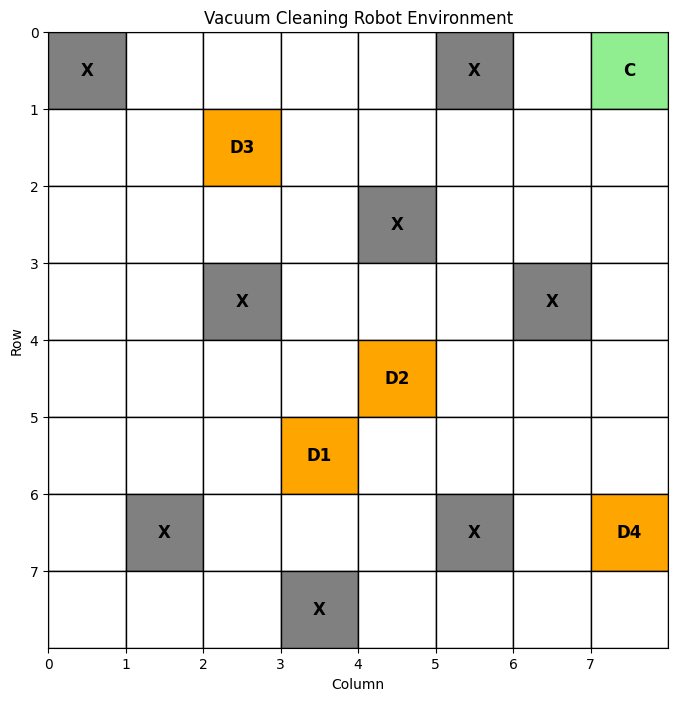

In [8]:
display_grid(grid)

In [9]:
def get_successors(state, grid):

    row, col = state

    moves = [
        (-1, 0, "UP"),
        (1, 0, "DOWN"),
        (0, -1, "LEFT"),
        (0, 1, "RIGHT")
    ]

    successors = []

    for dr, dc, action in moves:

        new_row = row + dr
        new_col = col + dc

        next_state = (new_row, new_col)

        # Check grid boundaries and obstacles
        if (
            0 <= new_row < grid["rows"]
            and 0 <= new_col < grid["cols"]
            and next_state not in grid["obstacles"]
        ):

            successors.append((next_state, action, 1))

    return successors

In [10]:
environment_valid = validate_environment(grid)

Environment is VALID!


In [11]:
def goal_test(state, goal_state):

    return state == goal_state

In [12]:
def path_cost(path):

    if not path:
        return 0

    return len(path) - 1

In [13]:
example_path = [(0, 7), (1, 7), (1, 6), (2, 6)]

print("Path Cost:", path_cost(example_path))

Path Cost: 3


In [14]:
def heuristic(state, goal_state):

    row1, col1 = state
    row2, col2 = goal_state

    return abs(row1 - row2) + abs(col1 - col2)

In [15]:
print(heuristic((0, 7), (5, 3)))

9


# Intelligent Vacuum Cleaning Robot
## Comparison of BFS, GBFS and A* Search

This notebook loads the environment from Environment.txt and runs three
search algorithms on the same environment and the same start/goal pairs:

- Breadth-First Search (BFS): uninformed, expands cells level by level.
- Greedy Best-First Search (GBFS): informed, uses only h(n).
- A* Search: informed, uses f(n) = g(n) + h(n).

The algorithms are compared by path cost, nodes expanded, running time and
search behavior.

**Heuristic used:** Manhattan distance, h(n) = |row_n - row_goal| + |col_n - col_goal|.
The robot moves only UP, DOWN, LEFT and RIGHT with step cost 1, so Manhattan
distance never overestimates the true remaining cost (admissible) and satisfies
h(n) <= 1 + h(n') for every move (consistent). This guarantees that A* is
optimal, while GBFS uses the same heuristic but ignores the cost already
travelled.

## 7. Search Algorithms

The three algorithms below use the same helper functions defined above
(get_successors, goal_test, path_cost and heuristic) and return the same
output format: (path, cost, nodes_expanded). If no path exists, they return
(None, inf, nodes_expanded). Nodes are counted when they are expanded, after
the goal test, so the counts are comparable.

In [16]:
def breadth_first_search(start, goal, grid):
    """Breadth-First Search.
    Returns (path, cost, nodes_expanded).
    Returns (None, inf, nodes_expanded) if no path exists."""

    frontier = deque([start])      # FIFO queue
    parent = {start: None}         # parent links and discovered set
    nodes_expanded = 0

    while frontier:
        current = frontier.popleft()

        # Goal test
        if goal_test(current, goal):
            path = []
            state = current
            while state is not None:
                path.append(state)
                state = parent[state]
            path.reverse()
            return path, path_cost(path), nodes_expanded

        # Expand the node
        nodes_expanded += 1

        for next_state, action, step_cost in get_successors(current, grid):
            if next_state not in parent:
                parent[next_state] = current
                frontier.append(next_state)

    # No path found
    return None, float("inf"), nodes_expanded

In [17]:
def greedy_best_first_search(start, goal, grid):
    """Greedy Best-First Search ordered by h(n) only.
    Returns (path, cost, nodes_expanded).
    Returns (None, inf, nodes_expanded) if no path exists."""

    # Priority queue: (heuristic, tie_breaker, state)
    priority_queue = []
    counter = itertools.count()

    heapq.heappush(
        priority_queue,
        (heuristic(start, goal), next(counter), start)
    )

    visited = set()
    discovered = {start}
    parent = {start: None}
    nodes_expanded = 0

    while priority_queue:
        h_value, _, current = heapq.heappop(priority_queue)

        if current in visited:
            continue

        visited.add(current)

        # Goal test
        if goal_test(current, goal):
            path = []
            state = current
            while state is not None:
                path.append(state)
                state = parent[state]
            path.reverse()
            return path, path_cost(path), nodes_expanded

        # Expand the node
        nodes_expanded += 1

        for next_state, action, step_cost in get_successors(current, grid):
            if next_state not in discovered:
                discovered.add(next_state)
                parent[next_state] = current
                h = heuristic(next_state, goal)
                heapq.heappush(
                    priority_queue,
                    (h, next(counter), next_state)
                )

    # No path found
    return None, float("inf"), nodes_expanded

In [18]:
def A_star_search(start, goal, grid):
    """A* Search using f(n) = g(n) + h(n) with Manhattan distance.
    Returns (path, cost, nodes_expanded).
    Returns (None, inf, nodes_expanded) if no path exists."""

    counter = itertools.count()    # tie-breaker for equal priorities
    start_h = heuristic(start, goal)

    # Priority queue entries: (f, h, insertion_order, state)
    frontier = [(start_h, start_h, next(counter), start)]
    g_score = {start: 0}           # cheapest known cost to each cell
    parent = {start: None}         # parent links for path reconstruction
    closed = set()                 # cells already expanded
    nodes_expanded = 0

    while frontier:
        f, h, _, current = heapq.heappop(frontier)

        # Skip stale entries (a cheaper route was already expanded)
        if current in closed:
            continue

        # Goal test
        if goal_test(current, goal):
            path = []
            state = current
            while state is not None:
                path.append(state)
                state = parent[state]
            path.reverse()
            return path, path_cost(path), nodes_expanded

        # Expand the node
        closed.add(current)
        nodes_expanded += 1

        for next_state, action, step_cost in get_successors(current, grid):
            new_g = g_score[current] + step_cost

            if next_state not in g_score or new_g < g_score[next_state]:
                g_score[next_state] = new_g
                parent[next_state] = current
                new_h = heuristic(next_state, goal)
                heapq.heappush(
                    frontier,
                    (new_g + new_h, new_h, next(counter), next_state)
                )

    # No path found
    return None, float("inf"), nodes_expanded

### 7.1 Search Function

The search() function selects the algorithm by name, so the same
grid, start and goal can be passed to any of the three algorithms.
Accepted names are "BFS", "GBFS" and "A*".

In [19]:
ALGORITHMS = {
    "BFS": breadth_first_search,
    "GBFS": greedy_best_first_search,
    "A*": A_star_search,
}

def search(grid, start, goal, algorithm="A*"):
    """Runs the selected search algorithm.
    Returns (path, cost, nodes_expanded)."""

    name = algorithm.upper().strip()

    if name not in ALGORITHMS:
        raise ValueError(
            f"Unsupported algorithm: {algorithm}. "
            f"Choose from {list(ALGORITHMS)}"
        )

    return ALGORITHMS[name](start, goal, grid)

## 8. Comparison of the Algorithms

### 8.1 Results Table

Every algorithm is run from the charging station to each dirty location.
For each run the table shows the path cost, the number of nodes expanded
and the running time. The time is the average of 200 repetitions, so it is
only a rough indication on such a small grid; path cost and nodes expanded
are the main measures.

In [20]:
import time

def timed_search(grid, start, goal, algorithm, repeats=200):
    """Runs a search once for its result and repeats it to average the time (ms)."""
    path, cost, expanded = search(grid, start, goal, algorithm)

    begin = time.perf_counter()
    for _ in range(repeats):
        search(grid, start, goal, algorithm)
    elapsed_ms = (time.perf_counter() - begin) / repeats * 1000

    return path, cost, expanded, elapsed_ms


start = grid["charging_station"]
results = {}      # results[(goal_index, algorithm)] = (path, cost, expanded, ms)

if environment_valid:
    header = f"{'Goal':<14}{'Algorithm':<11}{'Cost':<7}{'Expanded':<10}{'Time (ms)':<10}"
    print(header)
    print("-" * len(header))

    for index, goal in enumerate(grid["dirty_locations"]):
        for algorithm in ALGORITHMS:
            result = timed_search(grid, start, goal, algorithm)
            results[(index, algorithm)] = result
            path, cost, expanded, ms = result
            print(f"{'D' + str(index + 1) + ' ' + str(goal):<14}"
                  f"{algorithm:<11}{cost:<7}{expanded:<10}{ms:<10.4f}")
        print()

Goal          Algorithm  Cost   Expanded  Time (ms) 
----------------------------------------------------
D1 (5, 3)     BFS        9      39        0.2232    
D1 (5, 3)     GBFS       9      9         0.1080    
D1 (5, 3)     A*         9      9         0.0821    

D2 (4, 4)     BFS        7      26        0.2058    
D2 (4, 4)     GBFS       7      7         0.0510    
D2 (4, 4)     A*         7      7         0.0532    

D3 (1, 2)     BFS        6      22        0.0924    
D3 (1, 2)     GBFS       6      6         0.0432    
D3 (1, 2)     A*         6      6         0.0507    

D4 (6, 7)     BFS        6      16        0.0728    
D4 (6, 7)     GBFS       6      6         0.0425    
D4 (6, 7)     A*         6      6         0.0851    



### 8.2 Charts: Path Cost and Nodes Expanded

The bar charts show the path cost and the number of nodes expanded for each
dirty location. Equal bars in the cost chart mean the algorithms found paths
of the same length.

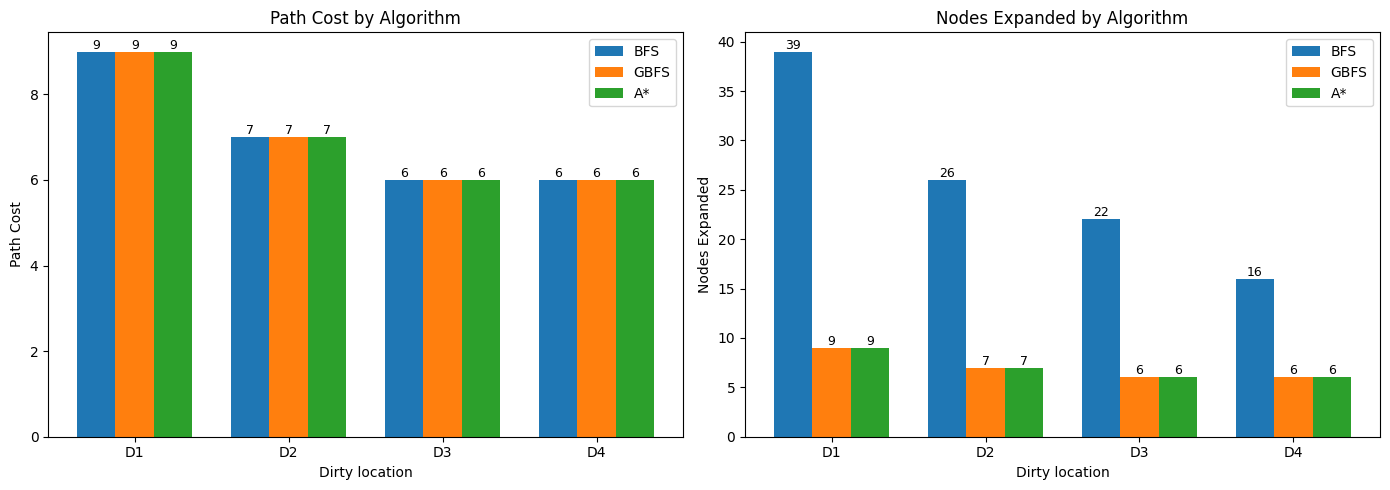

In [21]:
labels = [f"D{i + 1}" for i in range(len(grid["dirty_locations"]))]
x_positions = range(len(labels))
width = 0.25

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for metric_index, (title, axis) in enumerate(
        [("Path Cost", axes[0]), ("Nodes Expanded", axes[1])]):

    for k, algorithm in enumerate(ALGORITHMS):
        values = [results[(i, algorithm)][1 + metric_index]
                  for i in range(len(labels))]
        bars = axis.bar([p + (k - 1) * width for p in x_positions],
                        values, width, label=algorithm)
        axis.bar_label(bars, fontsize=9)

    axis.set_xticks(list(x_positions))
    axis.set_xticklabels(labels)
    axis.set_xlabel("Dirty location")
    axis.set_ylabel(title)
    axis.set_title(f"{title} by Algorithm")
    axis.legend()

plt.tight_layout()
plt.show()

### 8.3 Side-by-Side Search Behavior

Each row is one dirty location and each column one algorithm. The blue
line is the path returned, and the light blue cells are the cells the
algorithm expanded. This shows how each algorithm explores the grid:

- BFS expands cells in all directions, level by level.
- GBFS and A* are pulled towards the goal by the heuristic.

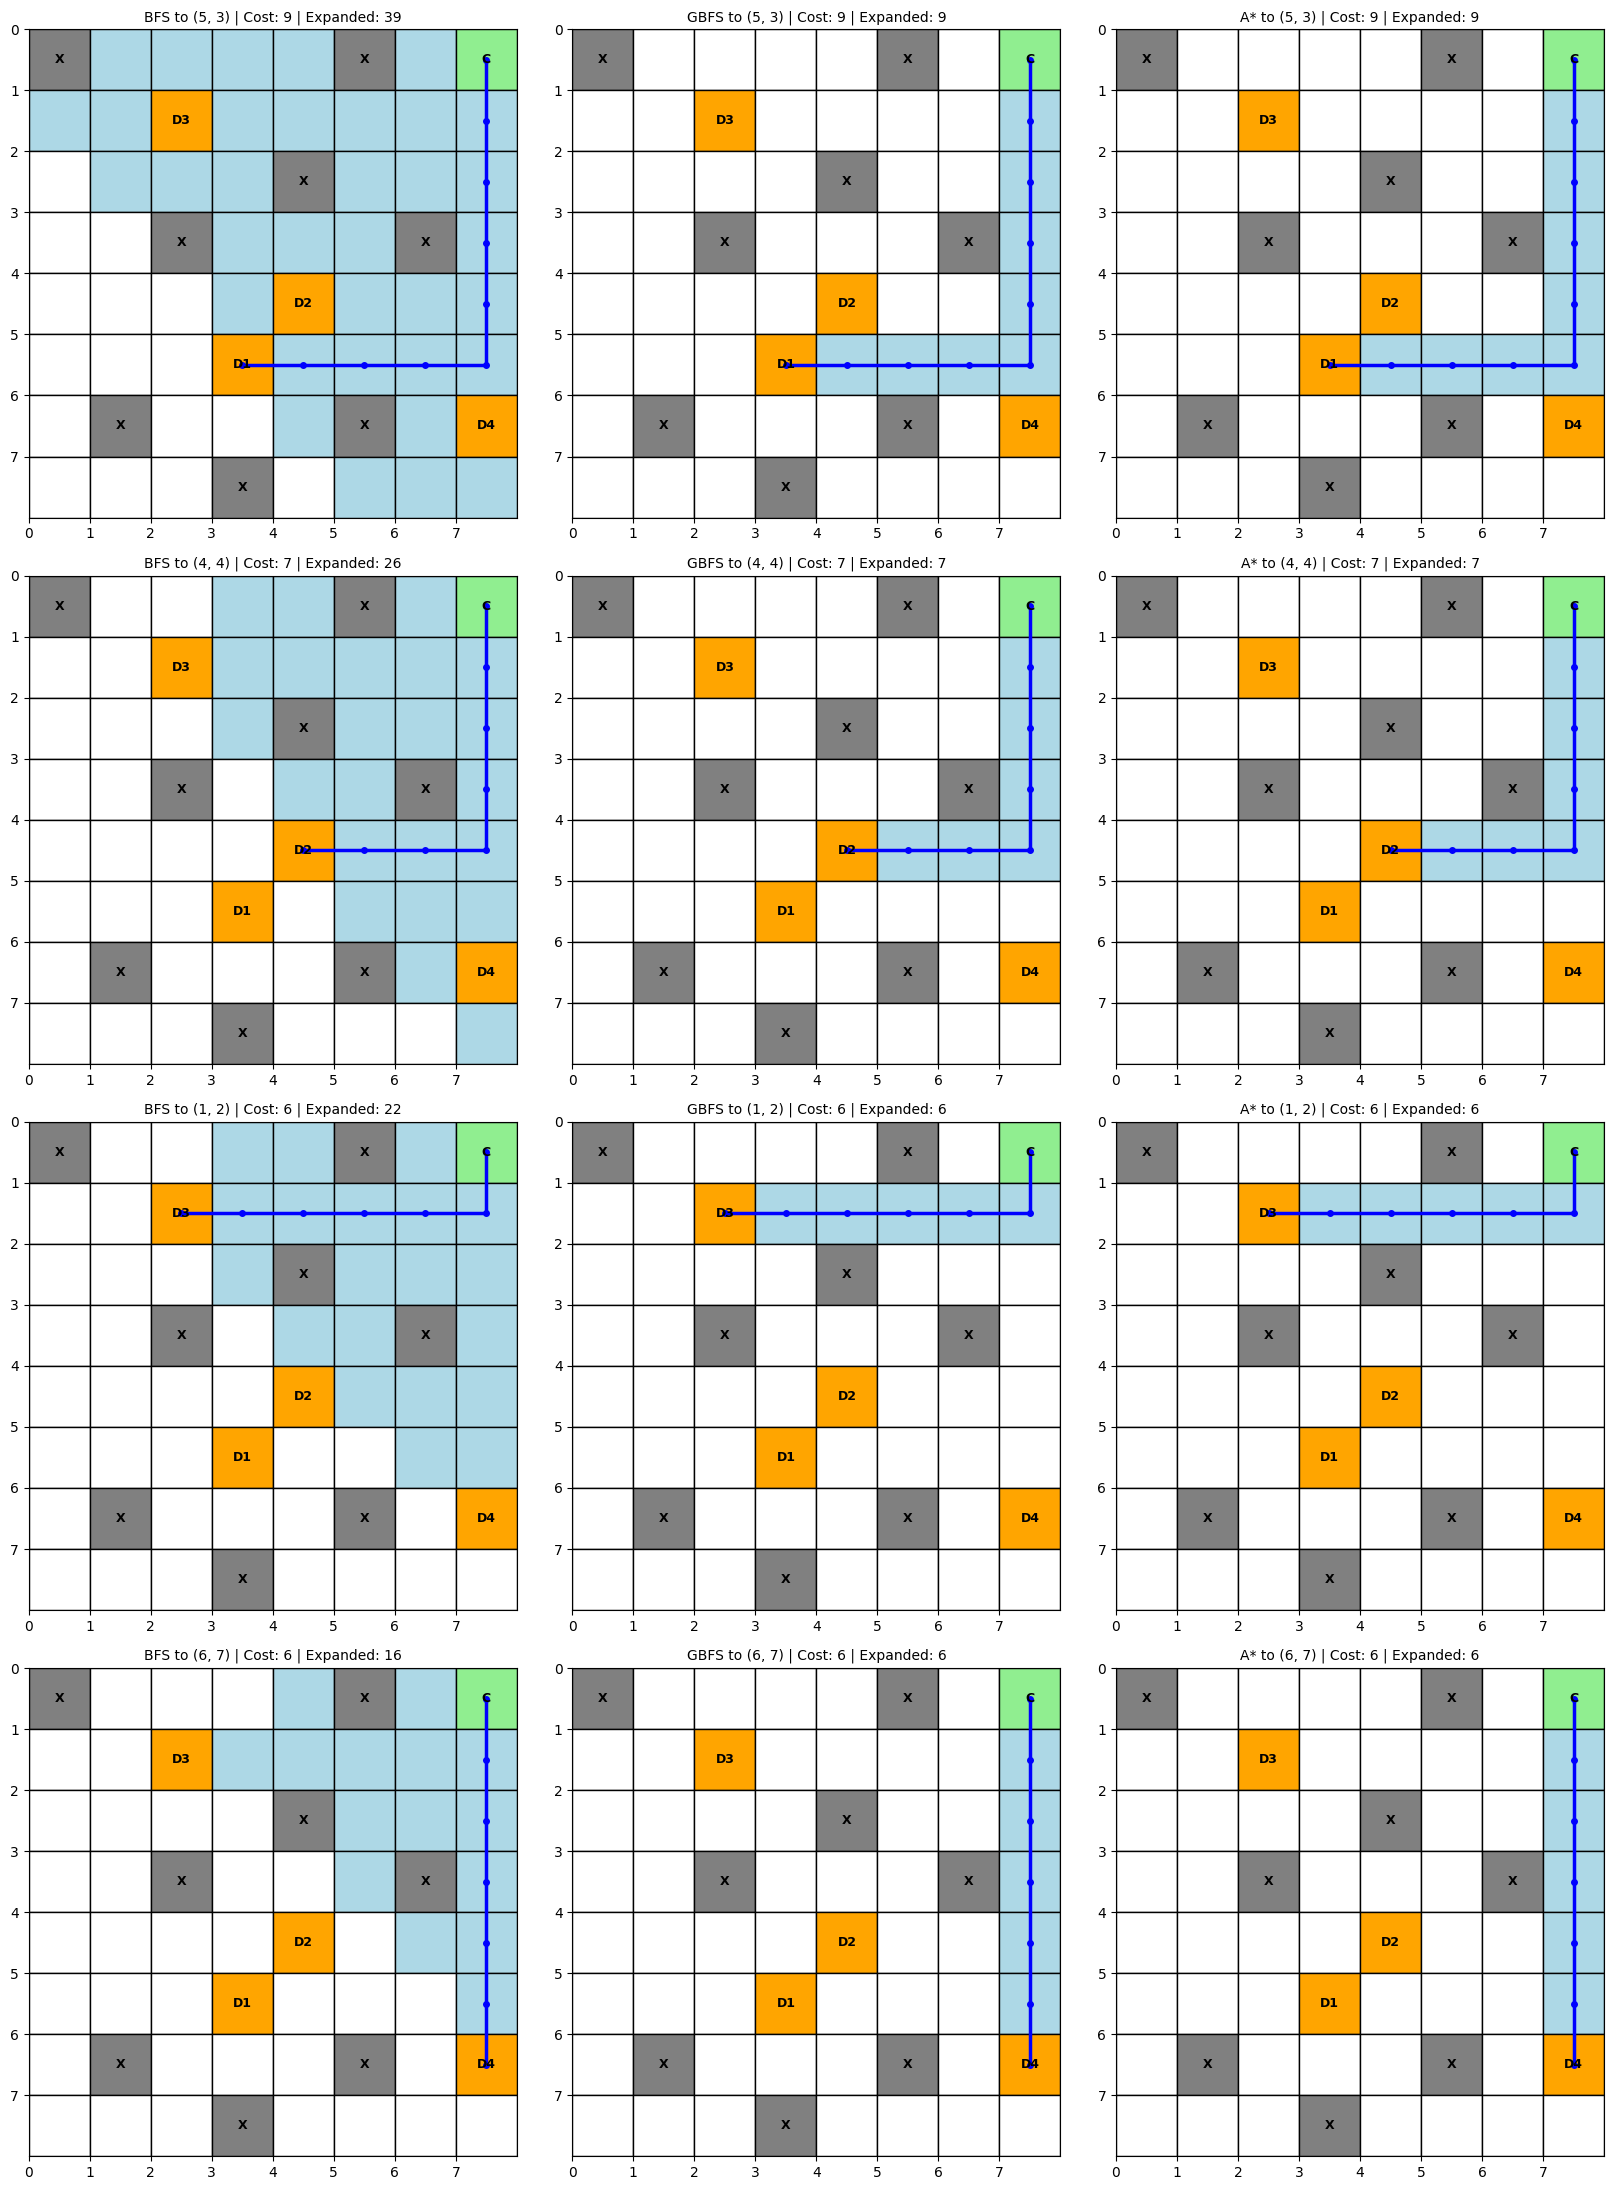

In [22]:
def expanded_cells(algorithm, start, goal, grid):
    """Returns the cells expanded by the chosen algorithm, in order.
    Uses the same logic as the search functions, so the length of the
    list equals nodes_expanded."""
    name = algorithm.upper().strip()
    expanded = []
    counter = itertools.count()

    if name == "BFS":
        frontier = deque([start])
        discovered = {start}
        while frontier:
            current = frontier.popleft()
            if goal_test(current, goal):
                break
            expanded.append(current)
            for nxt, action, cost in get_successors(current, grid):
                if nxt not in discovered:
                    discovered.add(nxt)
                    frontier.append(nxt)

    elif name == "GBFS":
        queue = [(heuristic(start, goal), next(counter), start)]
        visited, discovered = set(), {start}
        while queue:
            h, _, current = heapq.heappop(queue)
            if current in visited:
                continue
            visited.add(current)
            if goal_test(current, goal):
                break
            expanded.append(current)
            for nxt, action, cost in get_successors(current, grid):
                if nxt not in discovered:
                    discovered.add(nxt)
                    heapq.heappush(queue, (heuristic(nxt, goal), next(counter), nxt))

    elif name == "A*":
        h0 = heuristic(start, goal)
        queue = [(h0, h0, next(counter), start)]
        g_score, closed = {start: 0}, set()
        while queue:
            f, h, _, current = heapq.heappop(queue)
            if current in closed:
                continue
            if goal_test(current, goal):
                break
            closed.add(current)
            expanded.append(current)
            for nxt, action, cost in get_successors(current, grid):
                new_g = g_score[current] + cost
                if nxt not in g_score or new_g < g_score[nxt]:
                    g_score[nxt] = new_g
                    new_h = heuristic(nxt, goal)
                    heapq.heappush(queue, (new_g + new_h, new_h, next(counter), nxt))

    return expanded


def draw_search_on_axis(ax, grid, path, explored, title):
    rows, cols = grid["rows"], grid["cols"]
    ax.set_xlim(0, cols)
    ax.set_ylim(rows, 0)
    ax.set_aspect("equal")

    for r in range(rows):
        for c in range(cols):
            color, label = "white", ""
            if (r, c) in grid["obstacles"]:
                color, label = "gray", "X"
            elif (r, c) in grid["dirty_locations"]:
                color = "orange"
                label = f"D{grid['dirty_locations'].index((r, c)) + 1}"
            elif (r, c) == grid["charging_station"]:
                color, label = "lightgreen", "C"
            elif (r, c) in explored:
                color = "lightblue"

            ax.add_patch(plt.Rectangle((c, r), 1, 1,
                         facecolor=color, edgecolor="black"))
            if label:
                ax.text(c + 0.5, r + 0.5, label, ha="center",
                        va="center", fontsize=9, fontweight="bold")

    if path:
        xs = [col + 0.5 for row, col in path]
        ys = [row + 0.5 for row, col in path]
        ax.plot(xs, ys, color="blue", linewidth=2.5, marker="o", markersize=4)

    ax.set_xticks(range(cols))
    ax.set_yticks(range(rows))
    ax.set_title(title, fontsize=10)


def compare_visually(grid, start, goals):
    """One row per goal, one column per algorithm."""
    n_rows, n_cols = len(goals), len(ALGORITHMS)
    fig, axes = plt.subplots(n_rows, n_cols,
                             figsize=(5.5 * n_cols, 5.5 * n_rows),
                             squeeze=False)

    for i, goal in enumerate(goals):
        for j, algorithm in enumerate(ALGORITHMS):
            path, cost, expanded = search(grid, start, goal, algorithm)
            explored = set(expanded_cells(algorithm, start, goal, grid)) if path else set()
            draw_search_on_axis(
                axes[i][j], grid, path, explored,
                f"{algorithm} to {goal} | Cost: {cost} | Expanded: {expanded}"
            )

    plt.tight_layout()
    plt.show()


compare_visually(grid, grid["charging_station"], grid["dirty_locations"])

### 8.4 Path Validity Check

Every returned path must start at the start cell, end at the goal, contain only
adjacent cells inside the grid and never pass through an obstacle. The check
below is run for every algorithm on every ordered pair of important locations
(the charging station and all dirty locations). It also confirms that the
cost equals the number of moves and that the plotted explored cells match the
reported nodes_expanded.

In [23]:
def is_valid_path(path, start, goal, grid):
    """True if the path is a valid sequence of adjacent free cells."""
    if not path or path[0] != start or path[-1] != goal:
        return False
    for (r1, c1), (r2, c2) in zip(path, path[1:]):
        if abs(r1 - r2) + abs(c1 - c2) != 1:
            return False
    for r, c in path:
        if not (0 <= r < grid["rows"] and 0 <= c < grid["cols"]):
            return False
        if (r, c) in grid["obstacles"]:
            return False
    return True


points = [grid["charging_station"]] + grid["dirty_locations"]
pairs = [(a, b) for a in points for b in points if a != b]

all_valid = True
for algorithm in ALGORITHMS:
    for a, b in pairs:
        path, cost, expanded = search(grid, a, b, algorithm)
        ok = (is_valid_path(path, a, b, grid)
              and cost == len(path) - 1
              and expanded == len(expanded_cells(algorithm, a, b, grid)))
        if not ok:
            all_valid = False
            print("Problem:", algorithm, a, b)

print(f"Checked {len(pairs)} start/goal pairs for each of {len(ALGORITHMS)} algorithms.")
print("All paths valid:", all_valid)

Checked 20 start/goal pairs for each of 3 algorithms.
All paths valid: True


### 8.5 Average Performance Over All Pairs

To avoid judging from only four goals, each algorithm is run on every ordered
pair of the charging station and the dirty locations. The table shows the
average path cost, the average number of nodes expanded and how many times
each algorithm returned a path that was longer than the shortest one (found by
BFS, which is optimal when every move costs 1).

In [24]:
shortest = {(a, b): search(grid, a, b, "BFS")[1] for a, b in pairs}

header = f"{'Algorithm':<11}{'Avg Cost':<11}{'Avg Expanded':<15}{'Non-optimal paths'}"
print(header)
print("-" * 55)

for algorithm in ALGORITHMS:
    costs, expansions, non_optimal = [], [], 0
    for a, b in pairs:
        path, cost, expanded = search(grid, a, b, algorithm)
        costs.append(cost)
        expansions.append(expanded)
        if cost > shortest[(a, b)]:
            non_optimal += 1
    print(f"{algorithm:<11}{sum(costs) / len(costs):<11.2f}"
          f"{sum(expansions) / len(expansions):<15.2f}{non_optimal} of {len(pairs)}")

Algorithm  Avg Cost   Avg Expanded   Non-optimal paths
-------------------------------------------------------
BFS        6.00       31.05          0 of 20
GBFS       6.10       6.45           1 of 20
A*         6.00       6.50           0 of 20


### 8.6 Edge Cases for All Algorithms

Two cases are tested for every algorithm:
1. The start and goal are the same cell: the path has one cell, cost 0 and no nodes expanded.
2. The goal is completely surrounded by obstacles: no path exists, the cost is infinite and the algorithm stops after exploring every reachable cell.

In [25]:
blocked_grid = {
    "rows": 8,
    "cols": 8,
    "obstacles": {(2, 3), (3, 2), (3, 4), (4, 3)},
    "dirty_locations": [(3, 3)],
    "charging_station": (0, 0),
    "declared_obstacle_count": 4,
    "declared_dirty_count": 1
}

for algorithm in ALGORITHMS:
    print(f"--- {algorithm} ---")
    print("Start equals goal:", search(grid, start, start, algorithm))
    path, cost, expanded = search(blocked_grid, (0, 0), (3, 3), algorithm)
    print("Unreachable goal: Path =", path, "| Cost =", cost,
          "| Nodes Expanded =", expanded)
    print()

--- BFS ---
Start equals goal: ([(0, 7)], 0, 0)
Unreachable goal: Path = None | Cost = inf | Nodes Expanded = 59

--- GBFS ---
Start equals goal: ([(0, 7)], 0, 0)
Unreachable goal: Path = None | Cost = inf | Nodes Expanded = 59

--- A* ---
Start equals goal: ([(0, 7)], 0, 0)
Unreachable goal: Path = None | Cost = inf | Nodes Expanded = 59



## 9. Conclusion

The observations below are for the Environment.txt used in this notebook
(8 x 8 grid, charging station at (0, 7)). With a different environment file
the numbers will change, but the reasoning stays the same.

**Path cost**
- BFS and A* returned the shortest path in every test (D1 to D4 and all 20 start/goal pairs).
- GBFS matched the shortest cost for D1 to D4, but returned a longer path on 1 of the 20 pairs (average cost 6.10 against 6.00).

**Nodes expanded**
- BFS expanded 39, 26, 22 and 16 cells for D1 to D4, against 9, 7, 6 and 6 for GBFS and A*. On average over all pairs, BFS expanded about 31 cells, while GBFS and A* expanded about 6.5.
- On this environment GBFS and A* expanded almost the same number of cells, because the shortest path runs almost straight towards the goal.

**Behavior**
- BFS ignores the goal's position and spreads in all directions. It is complete and optimal, but it expands many unnecessary cells.
- GBFS ranks cells only by h(n). It is fast and focused, but it is not optimal because it never considers the cost already travelled.
- A* ranks cells by g(n) + h(n). Since the Manhattan heuristic is admissible and consistent here, A* is optimal and still expands far fewer cells than BFS.

**Running time**
- All three run in a fraction of a millisecond on this small grid, so timing differences are tiny and vary between runs. Nodes expanded is the more reliable measure of effort.

**Overall**
A* gives the best balance for this robot: the same optimal cost as BFS with about the same number of expanded cells as GBFS. GBFS is suitable only when speed matters more than getting the shortest path, and BFS is a safe baseline but wasteful on larger grids.